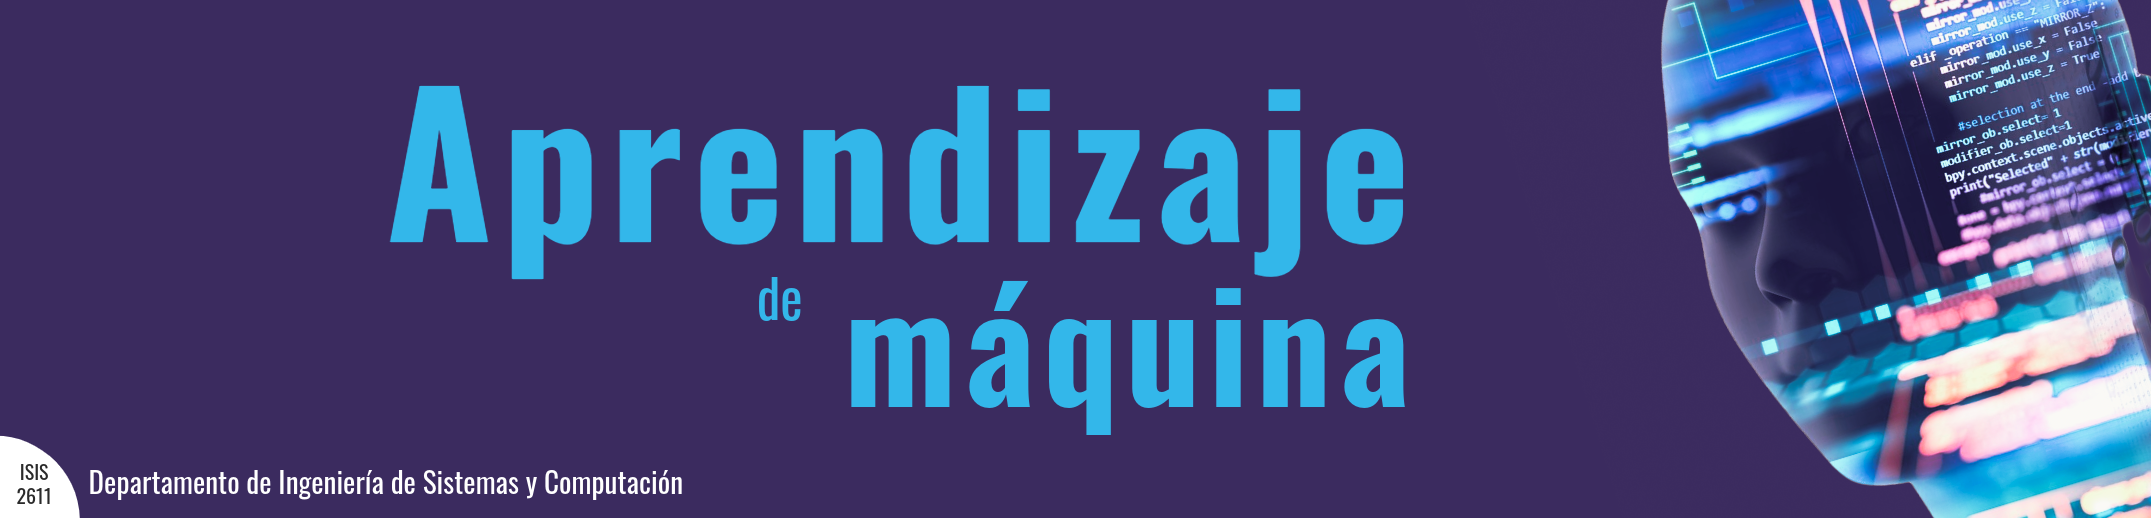

# Redes Neuronales Recurrentes: RNN, LSTM y GRU

En el notebook anterior construimos un **MLP** que clasifica imágenes estáticas:
recibe 784 píxeles sin importar el orden y produce una predicción.
Pero muchos problemas del mundo real son **secuenciales**: el significado depende
del orden — una palabra cambia de sentido según las que la rodean, y el precio
de mañana depende del de hoy.

Las **Redes Neuronales Recurrentes (RNN)** nacen para modelar exactamente eso:
datos donde el tiempo o el orden importan.

| Sección | Contenido |
|---------|-----------|
| 1 | Configuración del entorno |
| 2 | ¿Qué es una RNN? Intuición y arquitectura |
| 3 | El problema del vanishing gradient en RNNs |
| 4 | LSTM: memoria a largo plazo |
| 5 | GRU: versión simplificada |
| 6 | Caso práctico: predicción de series de tiempo (temperatura) |
| 7 | Comparación RNN vs LSTM vs GRU |
| 8 | Más allá de las RNNs: hacia los Transformers |
| 9 | Ejercicios |

## 1. Configuración del entorno

Usamos TensorFlow/Keras para construir los modelos recurrentes.
Se recomienda GPU en Google Colab: *Entorno de ejecución → Cambiar tipo → T4 GPU*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, HTML
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings; warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
tf.random.set_seed(42)
np.random.seed(42)
print(f'TensorFlow: {tf.__version__}')
print(f'GPU disponible: {len(tf.config.list_physical_devices("GPU")) > 0}')

TensorFlow: 2.20.0
GPU disponible: False


## 2. ¿Qué es una Red Neuronal Recurrente?

### 2.1 El problema de los datos secuenciales

Un MLP trata cada entrada como **independiente**: si le das las palabras de una frase
en orden aleatorio, produce la misma salida. Para un MLP, 'el gato comió al ratón'
y 'el ratón comió al gato' son equivalentes.

Los **datos secuenciales** son aquellos donde el orden importa:

| Dominio | Secuencia | Dependencia temporal |
|---------|-----------|---------------------|
| NLP | Palabras de una frase | El sujeto determina el verbo |
| Series de tiempo | Temperatura hora a hora | Hoy depende de ayer |
| Audio | Muestras de sonido | El fonema depende del anterior |
| Genómica | Bases de ADN | El codón determina el aminoácido |
| Finanzas | Precio diario de una acción | Tendencia acumulada |

### 2.2 La idea clave: estado oculto (*hidden state*)

Una RNN procesa la secuencia **paso a paso** y mantiene un **estado oculto** $h_t$
que actúa como memoria: resume todo lo que la red ha visto hasta el paso $t$.

$$h_t = \tanh(W_h \cdot h_{t-1} + W_x \cdot x_t + b)$$
$$\hat{y}_t = W_y \cdot h_t + b_y$$

donde:
- $x_t$ es la entrada en el paso $t$
- $h_{t-1}$ es el estado oculto del paso anterior (la **memoria**)
- $W_h, W_x$ son pesos compartidos en todos los pasos de tiempo

> **Los pesos se comparten entre pasos**: la misma transformación se aplica en cada
> instante de tiempo. Esto es lo que permite a la RNN procesar secuencias de
> longitud variable con un número fijo de parámetros.

### 2.3 Analogía: leer un libro

Imagina que lees un libro y alguien te pregunta de qué trata en cualquier momento.
Tu respuesta depende de **todo lo que has leído hasta ese punto** — no solo de la
última página. Tu memoria de lo anterior es el **estado oculto** de la RNN.

Un MLP sería equivalente a leer cada página con amnesia total de las anteriores.

### 2.4 Visualización interactiva: cómo fluye la información en una RNN

El siguiente widget muestra cómo el estado oculto $h_t$ se actualiza paso a paso.
Ajusta la longitud de la secuencia para ver el desenrollado de la red.

In [2]:
def dibujar_rnn_desenrollada(T=5, mostrar_y=True):
    fig, ax = plt.subplots(figsize=(max(10, T * 2.2), 5))
    ax.set_xlim(-0.5, T + 0.5)
    ax.set_ylim(-0.8, 3.2)
    ax.axis('off')

    colores = {'x': '#4C6EF5', 'h': '#2ECC71', 'y': '#FF6B6B'}
    r = 0.28

    for t in range(T):
        cx = t + 0.5
        # Nodo h_t
        circle_h = plt.Circle((cx, 1.5), r, color=colores['h'],
                               ec='white', lw=2, zorder=3)
        ax.add_patch(circle_h)
        ax.text(cx, 1.5, f'h$_{t}$', ha='center', va='center',
                fontsize=9, fontweight='bold', color='white', zorder=4)

        # Nodo x_t
        circle_x = plt.Circle((cx, 0.2), r, color=colores['x'],
                               ec='white', lw=2, zorder=3)
        ax.add_patch(circle_x)
        ax.text(cx, 0.2, f'x$_{t}$', ha='center', va='center',
                fontsize=9, fontweight='bold', color='white', zorder=4)

        # Flecha x_t → h_t
        ax.annotate('', xy=(cx, 1.5 - r), xytext=(cx, 0.2 + r),
                    arrowprops=dict(arrowstyle='->', color='#4C6EF5', lw=1.8))

        # Flecha h_{t-1} → h_t
        if t > 0:
            ax.annotate('', xy=(cx - r, 1.5), xytext=(cx - 0.44 + r, 1.5),
                        arrowprops=dict(arrowstyle='->', color='#2ECC71', lw=2))
            ax.text(cx - 0.22, 1.72, f'W$_h$', ha='center', fontsize=8,
                    color='#2ECC71', style='italic')

        # Nodo y_t
        if mostrar_y:
            circle_y = plt.Circle((cx, 2.8), r, color=colores['y'],
                                   ec='white', lw=2, zorder=3)
            ax.add_patch(circle_y)
            ax.text(cx, 2.8, f'ŷ$_{t}$', ha='center', va='center',
                    fontsize=9, fontweight='bold', color='white', zorder=4)
            ax.annotate('', xy=(cx, 2.8 - r), xytext=(cx, 1.5 + r),
                        arrowprops=dict(arrowstyle='->', color='#FF6B6B', lw=1.8))

    # h_0 (estado inicial)
    ax.text(0.08, 1.5, 'h$_0$=0', ha='center', va='center',
            fontsize=9, color='gray', style='italic')

    # Leyenda
    from matplotlib.patches import Patch
    leyenda = [Patch(color='#4C6EF5', label='Entrada xₜ'),
               Patch(color='#2ECC71', label='Estado oculto hₜ'),
               Patch(color='#FF6B6B', label='Salida ŷₜ')]
    ax.legend(handles=leyenda, loc='upper left', fontsize=9)

    ax.set_title(f'RNN desenrollada — {T} pasos de tiempo\n'
                 f'Los pesos W_h y W_x son los MISMOS en cada paso',
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()

widgets.interact(
    dibujar_rnn_desenrollada,
    T=widgets.IntSlider(value=5, min=2, max=10, step=1,
                         description='Pasos T:', continuous_update=False,
                         style={'description_width': '80px'}),
    mostrar_y=widgets.Checkbox(value=True, description='Mostrar salida ŷₜ'),
)

interactive(children=(IntSlider(value=5, continuous_update=False, description='Pasos T:', max=10, min=2, style…

> **Qué observar**: la flecha verde horizontal que conecta $h_{t-1}$ con $h_t$ es
> el **mecanismo recurrente** — la memoria que viaja a través del tiempo.
> Todos esos pasos usan exactamente los mismos pesos $W_h$ y $W_x$.

### 2.5 Ejemplo numérico: RNN paso a paso

Antes de usar Keras, implementamos una RNN mínima desde cero para ver exactamente
qué cálculos ocurren en cada paso de tiempo.

In [3]:
# RNN mínima: 1 neurona de entrada, 3 neuronas ocultas, 1 de salida
np.random.seed(0)

n_hidden = 3
W_x = np.random.randn(1, n_hidden) * 0.5      # pesos entrada → oculta
W_h = np.random.randn(n_hidden, n_hidden) * 0.5  # pesos oculta → oculta
b_h = np.zeros(n_hidden)                       # bias oculta
W_y = np.random.randn(n_hidden, 1) * 0.5       # pesos oculta → salida
b_y = np.zeros(1)

# Secuencia de entrada: [1, 2, 3, 4] (e.g., temperatura de 4 horas)
secuencia = [1.0, 2.0, 3.0, 4.0]
h = np.zeros(n_hidden)   # estado oculto inicial

print('Procesando secuencia paso a paso:',  secuencia)
print(f'Estado inicial h = {h}\n')

for t, x_t in enumerate(secuencia):
    h_prev = h.copy()
    h = np.tanh(x_t * W_x + h_prev @ W_h + b_h)[0]
    y_t = h @ W_y + b_y
    print(f'Paso t={t}: x={x_t}')
    print(f'  h = tanh(x·Wx + h_prev·Wh + b) = {h.round(4)}')
    print(f'  ŷ = h·Wy + by                  = {y_t[0]:.4f}')
    print()

print('El estado oculto final resume TODA la secuencia.')
print('La predicción final se basa en ese resumen acumulado.')

Procesando secuencia paso a paso: [1.0, 2.0, 3.0, 4.0]
Estado inicial h = [0. 0. 0.]

Paso t=0: x=1.0
  h = tanh(x·Wx + h_prev·Wh + b) = [0.7074 0.1975 0.4537]
  ŷ = h·Wy + by                  = 0.3819

Paso t=1: x=2.0
  h = tanh(x·Wx + h_prev·Wh + b) = [0.9918 0.7926 0.741 ]
  ŷ = h·Wy + by                  = 0.5901

Paso t=2: x=3.0
  h = tanh(x·Wx + h_prev·Wh + b) = [0.9996 0.9086 0.9017]
  ŷ = h·Wy + by                  = 0.6358

Paso t=3: x=4.0
  h = tanh(x·Wx + h_prev·Wh + b) = [0.9999 0.939  0.9691]
  ŷ = h·Wy + by                  = 0.6527

El estado oculto final resume TODA la secuencia.
La predicción final se basa en ese resumen acumulado.


####  Ejercicio 1 — Comprender el estado oculto

1. En el ejemplo numérico, ¿el estado oculto $h_3$ contiene información
   del paso $t=0$ (valor 1.0)? ¿Cómo llega esa información hasta el final?
2. Cambia la secuencia a `[4, 3, 2, 1]` (orden inverso). ¿Cambia el estado oculto
   final? ¿Qué dice eso sobre la sensibilidad de la RNN al orden?
3. ¿Qué pasaría si inicializaras $h_0$ con valores distintos de cero?
   ¿En qué situaciones tendría sentido hacerlo?

In [4]:
# Scaffold Ejercicio 1

# Punto 2: secuencia invertida
secuencia_inv = [4.0, 3.0, 2.0, 1.0]
h_inv = np.zeros(n_hidden)
for t, x_t in enumerate(secuencia_inv):
    h_inv = np.tanh(x_t * W_x + h_inv @ W_h + b_h)[0]

print('Estado oculto final con [1,2,3,4]:', h.round(4))
print('Estado oculto final con [4,3,2,1]:', h_inv.round(4))
print('Son iguales?', np.allclose(h, h_inv))
print()
print('Conclusion: el ORDEN de la secuencia importa — la RNN es sensible a el.')

# Punto 3: responde como comentario
# Inicializar h0 != 0 tendria sentido cuando...

Estado oculto final con [1,2,3,4]: [0.9999 0.939  0.9691]
Estado oculto final con [4,3,2,1]: [0.9886 0.8091 0.4956]
Son iguales? False

Conclusion: el ORDEN de la secuencia importa — la RNN es sensible a el.


## 3. El problema del vanishing gradient en RNNs

### 3.1 ¿Por qué las RNNs simples tienen memoria corta?

Recuerda del notebook anterior que el vanishing gradient ocurre cuando los gradientes
se multiplican capa tras capa y se hacen cada vez más pequeños. En una RNN, el problema
es **análogo pero a través del tiempo**: el gradiente debe propagarse hacia atrás
por todos los pasos de tiempo (Backpropagation Through Time, BPTT).

Para calcular cómo el error en el paso $T$ afecta al peso $W_h$, necesitamos:

$$\frac{\partial L_T}{\partial W_h} = \sum_{t=1}^{T}
\frac{\partial L_T}{\partial h_T} \cdot
\prod_{k=t+1}^{T} \frac{\partial h_k}{\partial h_{k-1}} \cdot
\frac{\partial h_t}{\partial W_h}$$

El término $\prod_{k=t+1}^{T} \frac{\partial h_k}{\partial h_{k-1}}$
involucra la multiplicación repetida del **gradiente de la activación** por $W_h$.

- Si los valores propios de $W_h$ son $< 1$: gradiente → 0 (**vanishing**)
- Si los valores propios de $W_h$ son $> 1$: gradiente → ∞ (**exploding**)

### 3.2 Consecuencia práctica: dependencias a largo plazo

> **Analogía del teléfono roto**: imagina que necesitas transmitir un mensaje de
> 100 personas en cadena, y cada persona lo distorsiona ligeramente. Al llegar a
> la persona 100, el mensaje original es irreconocible. La RNN simple sufre lo mismo:
> la información del paso $t=1$ llega muy distorsionada al paso $t=100$.

**Ejemplo clásico**: en la frase
*'Las nubes que cubrían las montañas nevadas del norte de Colombia estaban __'*,
la RNN necesita recordar 'nubes' (muy atrás) para predecir 'blancas'. Una RNN simple
habrá 'olvidado' 'nubes' para cuando llegue al hueco.

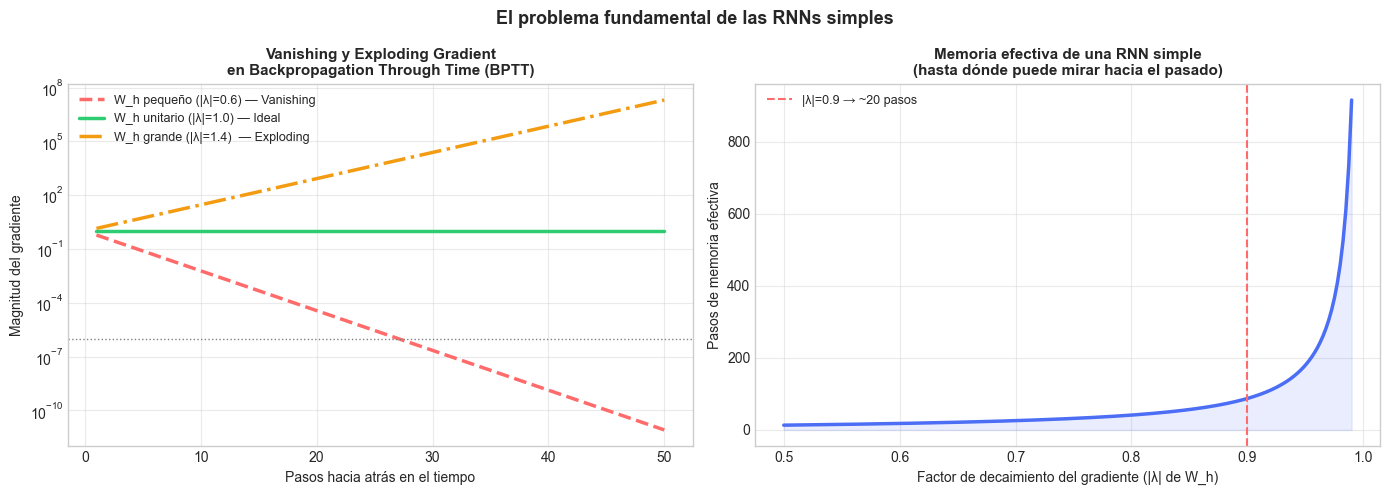

Con |lambda| = 0.9, el gradiente llega al paso 20 con magnitud ~e^(-4) ~ 0.018
Con |lambda| = 0.6, el gradiente prácticamente desaparece en 10 pasos.
Solucion: LSTM y GRU diseñan mecanismos para mantener el gradiente constante.


In [5]:
# Visualización del vanishing gradient en BPTT
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

T_pasos = np.arange(1, 51)

# Gradiente acumulado con distintos tamaños de W_h
escenarios = {
    'W_h pequeño (|λ|=0.6) — Vanishing': (0.6, '#FF6B6B', '--'),
    'W_h unitario (|λ|=1.0) — Ideal':    (1.0, '#2ECC71', '-'),
    'W_h grande (|λ|=1.4)  — Exploding': (1.4, '#F39C12', '-.'),
}

for nombre, (lam, color, ls) in escenarios.items():
    grads = lam ** T_pasos
    axes[0].plot(T_pasos, grads, color=color, lw=2.5, linestyle=ls, label=nombre)

axes[0].set_xlabel('Pasos hacia atrás en el tiempo', fontsize=10)
axes[0].set_ylabel('Magnitud del gradiente', fontsize=10)
axes[0].set_title('Vanishing y Exploding Gradient\nen Backpropagation Through Time (BPTT)',
                   fontsize=11, fontweight='bold')
axes[0].set_yscale('log')
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.4)
axes[0].axhline(1e-6, color='gray', linestyle=':', lw=1,
                label='Umbral de vanishing')

# Cuántos pasos de memoria efectiva según el factor
factores = np.linspace(0.5, 0.99, 200)
memoria_efectiva = np.log(1e-4) / np.log(factores)

axes[1].plot(factores, memoria_efectiva, color='#4C6EF5', lw=2.5)
axes[1].fill_between(factores, memoria_efectiva, alpha=0.12, color='#4C6EF5')
axes[1].set_xlabel('Factor de decaimiento del gradiente (|λ| de W_h)', fontsize=10)
axes[1].set_ylabel('Pasos de memoria efectiva', fontsize=10)
axes[1].set_title('Memoria efectiva de una RNN simple\n'
                   '(hasta dónde puede mirar hacia el pasado)',
                   fontsize=11, fontweight='bold')
axes[1].grid(alpha=0.4)
axes[1].axvline(0.9, color='#FF6B6B', linestyle='--', lw=1.5,
                label='|λ|=0.9 → ~20 pasos')
axes[1].legend(fontsize=9)

plt.suptitle('El problema fundamental de las RNNs simples',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Con |lambda| = 0.9, el gradiente llega al paso 20 con magnitud ~e^(-4) ~ 0.018')
print('Con |lambda| = 0.6, el gradiente prácticamente desaparece en 10 pasos.')
print('Solucion: LSTM y GRU diseñan mecanismos para mantener el gradiente constante.')

## 4. LSTM: Long Short-Term Memory

La **LSTM** fue propuesta por Hochreiter y Schmidhuber (1997) como solución directa
al problema del vanishing gradient. Su idea central: en lugar de dejar que la red
decida qué recordar implícitamente (como la RNN simple), equiparla con
**mecanismos explícitos de memoria** controlados por compuertas.

### 4.1 Dos tipos de memoria

Una LSTM mantiene **dos vectores de estado** en cada paso de tiempo:

| Estado | Notación | Función | Analogía |
|--------|----------|---------|---------|
| **Estado de celda** | $C_t$ | Memoria a largo plazo | El libro de notas permanente |
| **Estado oculto** | $h_t$ | Memoria a corto plazo / salida | Lo que acabas de escribir |

> **Analogía del libro de notas**: imagina que tienes un bloc permanente ($C_t$)
> donde anotas información importante, y un post-it ($h_t$) donde anotas lo
> que necesitas en el momento. Las compuertas controlan qué pasa del post-it al
> bloc, qué borras del bloc y qué lees de él.

### 4.2 Las tres compuertas

Las compuertas son funciones **Sigmoid** que producen valores entre 0 y 1.
Un valor de 0 significa 'bloquear completamente' y 1 significa 'dejar pasar todo'.

**1. Compuerta de olvido** (*forget gate*): decide qué borrar de $C_{t-1}$
$$f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$$

**2. Compuerta de entrada** (*input gate*): decide qué información nueva escribir
$$i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$$
$$\tilde{C}_t = \tanh(W_C \cdot [h_{t-1}, x_t] + b_C)$$

**3. Compuerta de salida** (*output gate*): decide qué leer de $C_t$
$$o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$$

**Actualización del estado de celda** (la clave del vanishing gradient):
$$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$$

Esta ecuación es fundamental: el gradiente fluye por la **suma** (no por una multiplicación
repetida), lo que permite que la información persista muchos pasos sin desvanecerse.

**Actualización del estado oculto:**
$$h_t = o_t \odot \tanh(C_t)$$

### 4.3 Visualización interactiva: las compuertas de la LSTM

El siguiente widget simula el comportamiento de las tres compuertas en un paso de tiempo.
Ajusta los valores de las compuertas y observa cómo afectan al estado de celda y
al estado oculto.

In [ ]:
def visualizar_lstm_gates(f_gate=0.7, i_gate=0.8, o_gate=0.9,
                           C_prev=0.5, h_prev=0.3, x_t=0.6):
    """Simula un paso de LSTM con compuertas controladas manualmente."""
    # Simulamos C_tilde como función de h_prev y x_t
    C_tilde = np.tanh(0.4 * h_prev + 0.6 * x_t)   # nueva candidata

    # Actualización del estado de celda
    C_t = f_gate * C_prev + i_gate * C_tilde
    C_t = np.clip(C_t, -1, 1)

    # Estado oculto
    h_t = o_gate * np.tanh(C_t)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # ── Panel 1: diagrama de compuertas ──────────────────────────────────────
    ax = axes[0]
    ax.set_xlim(0, 10); ax.set_ylim(0, 8)
    ax.axis('off')

    # Estado de celda (flujo horizontal superior)
    ax.annotate('', xy=(8.5, 6.5), xytext=(0.5, 6.5),
                arrowprops=dict(arrowstyle='->', color='#2ECC71', lw=3))
    ax.text(0.2, 6.5, f'C_prev\n{C_prev:.2f}', ha='center', va='center',
            fontsize=9, color='#2ECC71', fontweight='bold')
    ax.text(9.0, 6.5, f'C_t\n{C_t:.3f}', ha='center', va='center',
            fontsize=9, color='#2ECC71', fontweight='bold')

    # Compuertas
    gates_info = [
        (2.0, 'OLVIDO\n(forget)', f_gate, '#E74C3C',
         f'¿Qué borrar\nde C_prev?\n→ {f_gate:.0%} pasa'),
        (5.0, 'ENTRADA\n(input)', i_gate, '#3498DB',
         f'¿Qué escribir\nnuevo?\n→ {i_gate:.0%} pasa'),
        (8.0, 'SALIDA\n(output)', o_gate, '#9B59B6',
         f'¿Qué leer\nde C_t?\n→ {o_gate:.0%} pasa'),
    ]
    for gx, nombre, valor, color, desc in gates_info:
        circle = plt.Circle((gx, 6.5), 0.45, color=color,
                             alpha=valor, ec=color, lw=2, zorder=3)
        ax.add_patch(circle)
        ax.text(gx, 6.5, f'{valor:.2f}', ha='center', va='center',
                fontsize=11, fontweight='bold', color='white', zorder=4)
        ax.text(gx, 5.3, nombre, ha='center', fontsize=8, color=color,
                fontweight='bold')
        ax.text(gx, 4.5, desc, ha='center', fontsize=7.5, color='gray',
                style='italic')

    # C_tilde
    ax.text(5.0, 3.2, f'C̃_t (candidata)\n= tanh(...) = {C_tilde:.3f}',
            ha='center', fontsize=8, color='#3498DB',
            bbox=dict(boxstyle='round', fc='#EBF5FB', ec='#3498DB'))

    # h_t salida
    ax.text(5.0, 1.5,
            f'h_t = o_t · tanh(C_t)\n= {o_gate:.2f} · tanh({C_t:.3f}) = {h_t:.4f}',
            ha='center', fontsize=9, fontweight='bold', color='#8E44AD',
            bbox=dict(boxstyle='round', fc='#F5EEF8', ec='#8E44AD'))

    ax.set_title('Compuertas LSTM — un paso de tiempo',
                 fontsize=11, fontweight='bold')

    # ── Panel 2: barra de estado de celda ────────────────────────────────────
    valores = [C_prev, f_gate * C_prev, C_tilde, i_gate * C_tilde, C_t]
    etiquetas = ['C_prev\n(antes)', 'f·C_prev\n(tras olvido)',
                 'C̃_t\n(candidata)', 'i·C̃_t\n(entrada nueva)', 'C_t\n(resultado)']
    colores_bar = ['#2ECC71', '#E74C3C', '#3498DB', '#3498DB', '#27AE60']

    bars = axes[1].bar(etiquetas, valores, color=colores_bar, alpha=0.8,
                        edgecolor='white', lw=2)
    axes[1].axhline(0, color='gray', lw=0.8)
    axes[1].bar_label(bars, fmt='{:.3f}', fontsize=9)
    axes[1].set_ylim(-1.1, 1.1)
    axes[1].set_title('Evolución del estado de celda C_t\n'
                      f'= f·C_prev + i·C̃_t = {f_gate:.2f}·{C_prev:.2f} + {i_gate:.2f}·{C_tilde:.3f} = {C_t:.3f}',
                      fontsize=10, fontweight='bold')
    axes[1].set_ylabel('Valor del estado de celda')
    axes[1].grid(alpha=0.4, axis='y')

    plt.tight_layout()
    plt.show()

    print(f'Estado de celda: {C_prev:.3f} → {C_t:.3f}')
    print(f'Estado oculto: {h_prev:.3f} → {h_t:.4f}')
    if f_gate < 0.2:
        print('  Compuerta de olvido casi cerrada: se borra casi todo el pasado.')
    if i_gate < 0.2:
        print('  Compuerta de entrada casi cerrada: no se escribe información nueva.')

widgets.interact(
    visualizar_lstm_gates,
    f_gate=widgets.FloatSlider(value=0.7, min=0.0, max=1.0, step=0.05,
                                description='🔴 Olvido (f):', continuous_update=False,
                                style={'description_width': '120px'}),
    i_gate=widgets.FloatSlider(value=0.8, min=0.0, max=1.0, step=0.05,
                                description='🔵 Entrada (i):', continuous_update=False,
                                style={'description_width': '120px'}),
    o_gate=widgets.FloatSlider(value=0.9, min=0.0, max=1.0, step=0.05,
                                description='🟣 Salida (o):', continuous_update=False,
                                style={'description_width': '120px'}),
    C_prev=widgets.FloatSlider(value=0.5, min=-1.0, max=1.0, step=0.1,
                                description='C anterior:', continuous_update=False,
                                style={'description_width': '120px'}),
)

interactive(children=(FloatSlider(value=0.7, continuous_update=False, description='🔴 Olvido (f):', max=1.0, st…

> **Qué observar**:
> - Pon la compuerta de **olvido = 0**: el estado de celda anterior se borra completamente.
> - Pon la compuerta de **entrada = 0**: no se escribe ninguna información nueva.
> - Pon la compuerta de **olvido = 1 y entrada = 0**: la LSTM simplemente *copia* el estado anterior — así funciona la memoria a largo plazo.
> - La ecuación $C_t = f_t \cdot C_{t-1} + i_t \cdot \tilde{C}_t$ es una **suma ponderada**, no un producto encadenado. Por eso el gradiente no desaparece.

## 5. GRU: Gated Recurrent Unit

La **GRU** fue propuesta por Cho et al. (2014) como una simplificación de la LSTM.
Su motivación: ¿podemos conseguir la misma memoria a largo plazo con menos parámetros?

### 5.1 Diferencias con la LSTM

| | LSTM | GRU |
|---|------|-----|
| **Estados** | $h_t$ y $C_t$ (dos vectores) | Solo $h_t$ (un vector) |
| **Compuertas** | 3 (olvido, entrada, salida) | 2 (reset, actualización) |
| **Parámetros** | ~4× tamaño capa | ~3× tamaño capa |
| **Complejidad** | Mayor | Menor |
| **Rendimiento** | Ligeramente mejor en secuencias largas | Comparable en muchos casos |

### 5.2 Las dos compuertas de la GRU

**1. Compuerta de reset** ($r_t$): controla cuánto del estado pasado usar para
calcular el nuevo estado candidato. Si $r_t \approx 0$, la GRU actúa como si
empezara de nuevo (ignora el pasado).

$$r_t = \sigma(W_r \cdot [h_{t-1}, x_t] + b_r)$$
$$\tilde{h}_t = \tanh(W \cdot [r_t \odot h_{t-1}, x_t] + b)$$

**2. Compuerta de actualización** ($z_t$): decide cuánto del estado anterior
conservar vs. cuánto del nuevo candidato adoptar. **Combina las compuertas de
olvido y entrada de la LSTM en una sola.**

$$z_t = \sigma(W_z \cdot [h_{t-1}, x_t] + b_z)$$
$$h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$$

> **Analogía**: si la LSTM es como un secretario con un archivador (decide qué archivar,
> qué tirar y qué sacar), la GRU es como tomar notas en márgenes del mismo documento:
> más simple, menos separación entre memoria corta y larga, pero funciona sorprendentemente bien.

### 5.3 ¿Cuándo usar LSTM vs GRU?

- **GRU**: datasets pequeños, prototipado rápido, secuencias no muy largas.
- **LSTM**: secuencias largas con dependencias complejas, cuando hay suficiente datos
  para aprovechar la mayor capacidad de la LSTM.
- En la práctica, prueba ambos y elige según validación.

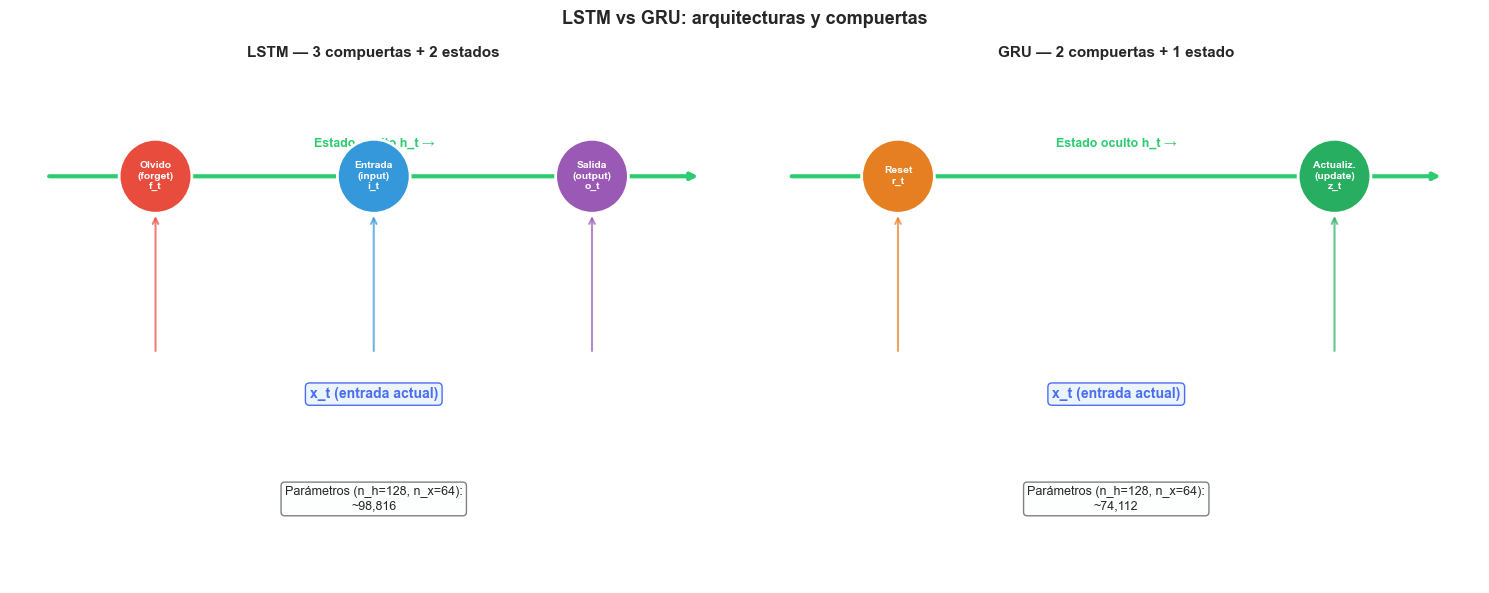

LSTM (128 unidades): ~98,816 parámetros
GRU  (128 unidades): ~74,112 parámetros
Reduccion: 25% menos parámetros con GRU


In [25]:
# Comparación visual: arquitectura LSTM vs GRU
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, titulo, compuertas, color_g in [
    (axes[0], 'LSTM — 3 compuertas + 2 estados',
     ['Olvido\n(forget)\nf_t', 'Entrada\n(input)\ni_t', 'Salida\n(output)\no_t'],
     ['#E74C3C', '#3498DB', '#9B59B6']),
    (axes[1], 'GRU — 2 compuertas + 1 estado',
     ['Reset\nr_t', 'Actualiz.\n(update)\nz_t'],
     ['#E67E22', '#27AE60']),
]:
    ax.set_xlim(0, 10); ax.set_ylim(0, 7)
    ax.axis('off')
    ax.set_title(titulo, fontsize=11, fontweight='bold')

    # Flujo horizontal (estado)
    ax.annotate('', xy=(9.5, 5.5), xytext=(0.5, 5.5),
                arrowprops=dict(arrowstyle='->', color='#2ECC71', lw=3))
    ax.text(5.0, 5.9, 'Estado oculto h_t →', ha='center',
            fontsize=9, color='#2ECC71', fontweight='bold')

    # Compuertas
    n = len(compuertas)
    xs = np.linspace(2, 8, n)
    for gx, nombre, color in zip(xs, compuertas, color_g):
        r_g = 0.5
        circle = plt.Circle((gx, 5.5), r_g, color=color, ec='white', lw=2, zorder=3)
        ax.add_patch(circle)
        ax.text(gx, 5.5, nombre, ha='center', va='center',
                fontsize=7.5, color='white', fontweight='bold', zorder=4)
        # Flecha desde x_t
        ax.annotate('', xy=(gx, 5.5 - r_g), xytext=(gx, 2.8 + 0.3),
                    arrowprops=dict(arrowstyle='->', color=color, lw=1.5, alpha=0.7))

    # Entrada x_t
    ax.text(5.0, 2.5, 'x_t (entrada actual)', ha='center',
            fontsize=10, color='#4C6EF5', fontweight='bold',
            bbox=dict(boxstyle='round', fc='#EBF5FB', ec='#4C6EF5'))

    # Parámetros
    n_h = 128
    n_x = 64
    if n == 3:
        params = 4 * (n_h * n_h + n_h * n_x + n_h)
        label = f'Parámetros (n_h={n_h}, n_x={n_x}):\n~{params:,}'
    else:
        params = 3 * (n_h * n_h + n_h * n_x + n_h)
        label = f'Parámetros (n_h={n_h}, n_x={n_x}):\n~{params:,}'
    ax.text(5.0, 1.0, label, ha='center', fontsize=9,
            bbox=dict(boxstyle='round', fc='#FDFEFE', ec='gray'))

plt.suptitle('LSTM vs GRU: arquitecturas y compuertas',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

n_h = 128; n_x = 64
params_lstm = 4 * (n_h * n_h + n_h * n_x + n_h)
params_gru  = 3 * (n_h * n_h + n_h * n_x + n_h)
print(f'LSTM ({n_h} unidades): ~{params_lstm:,} parámetros')
print(f'GRU  ({n_h} unidades): ~{params_gru:,} parámetros')
print(f'Reduccion: {(1 - params_gru/params_lstm)*100:.0f}% menos parámetros con GRU')

## 6. Caso práctico: predicción de temperatura con series de tiempo

Aplicamos los tres modelos (RNN simple, LSTM, GRU) al problema de predecir la
**temperatura horaria** del aeropuerto de Bogotá usando datos históricos.

Usamos el dataset **Jena Climate Dataset** (disponible en Keras), que contiene
mediciones meteorológicas cada hora. Nos quedaremos solo con la temperatura.

**Tarea**: dado un historial de 24 horas, predecir la temperatura de la próxima hora.

### 6.1 Carga y exploración de los datos

In [26]:
import os
import ssl
import urllib.request
import zipfile

url = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip'
cache_dir = os.path.join(os.path.expanduser('~'), '.keras', 'datasets')
zip_path = os.path.join(cache_dir, 'jena_climate_2009_2016.csv.zip')
csv_path = os.path.join(cache_dir, 'jena_climate_2009_2016.csv')

os.makedirs(cache_dir, exist_ok=True)

if not os.path.exists(csv_path):
	if not os.path.exists(zip_path):
		context = ssl._create_unverified_context()
		with urllib.request.urlopen(url, context=context) as response, open(zip_path, 'wb') as out_file:
			out_file.write(response.read())

	with zipfile.ZipFile(zip_path, 'r') as zip_ref:
		zip_ref.extractall(cache_dir)

df_raw = pd.read_csv(csv_path)
print(f'Shape: {df_raw.shape}')
print(df_raw.head())

Shape: (420551, 15)
             Date Time  p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  \
0  01.01.2009 00:10:00    996.52     -8.02    265.40        -8.90    93.3   
1  01.01.2009 00:20:00    996.57     -8.41    265.01        -9.28    93.4   
2  01.01.2009 00:30:00    996.53     -8.51    264.91        -9.31    93.9   
3  01.01.2009 00:40:00    996.51     -8.31    265.12        -9.07    94.2   
4  01.01.2009 00:50:00    996.51     -8.27    265.15        -9.04    94.1   

   VPmax (mbar)  VPact (mbar)  VPdef (mbar)  sh (g/kg)  H2OC (mmol/mol)  \
0          3.33          3.11          0.22       1.94             3.12   
1          3.23          3.02          0.21       1.89             3.03   
2          3.21          3.01          0.20       1.88             3.02   
3          3.26          3.07          0.19       1.92             3.08   
4          3.27          3.08          0.19       1.92             3.09   

   rho (g/m**3)  wv (m/s)  max. wv (m/s)  wd (deg)  
0       1307.

In [27]:
# Usar solo la columna de temperatura (T (degC))
# Submuestrear a una medición por hora (originalmente cada 10 min)
df = df_raw[['Date Time', 'T (degC)']].copy()
df.columns = ['fecha', 'temperatura']
df = df.iloc[::6].reset_index(drop=True)  # cada hora
df['fecha'] = pd.to_datetime(df['fecha'], format='%d.%m.%Y %H:%M:%S')

print(f'Registros: {len(df):,}')
print(f'Periodo: {df.fecha.min()} → {df.fecha.max()}')
print(f'Temperatura min/max: {df.temperatura.min():.1f} / {df.temperatura.max():.1f} °C')
print(df.head())

Registros: 70,092
Periodo: 2009-01-01 00:10:00 → 2016-12-31 23:20:00
Temperatura min/max: -23.0 / 37.1 °C
                fecha  temperatura
0 2009-01-01 00:10:00        -8.02
1 2009-01-01 01:10:00        -7.62
2 2009-01-01 02:10:00        -8.85
3 2009-01-01 03:10:00        -8.84
4 2009-01-01 04:10:00        -9.23


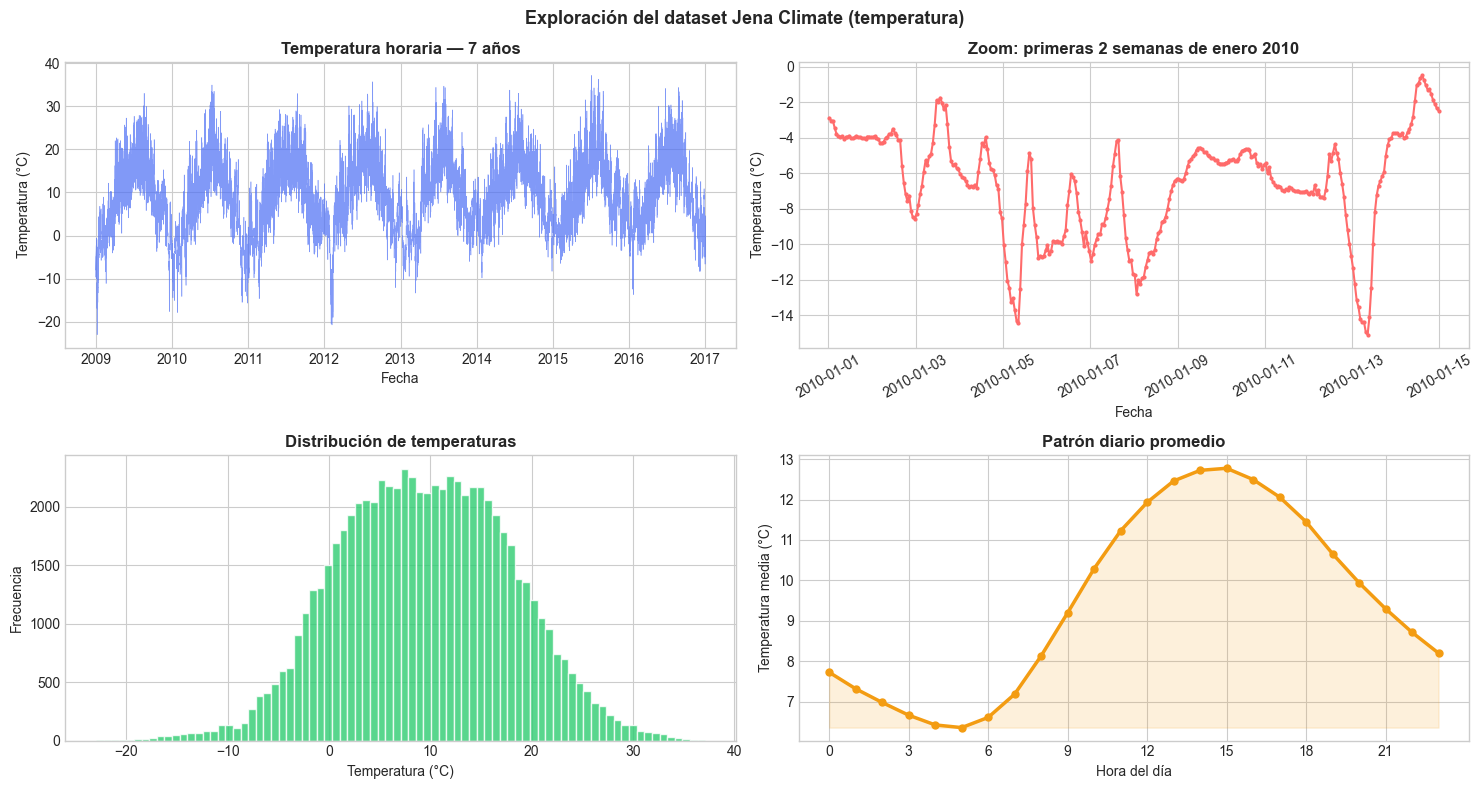

Autocorrelación en la serie:
  La temperatura tiene un patron diario fuerte (valle a las 5am, pico a las 2pm)
  Tambien tiene estacionalidad anual (veranos mas calidos, inviernos mas frios)
  Esta estructura temporal es exactamente lo que las RNNs deben aprender.


In [28]:
# Exploración visual
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

# Serie completa
axes[0, 0].plot(df['fecha'], df['temperatura'], color='#4C6EF5',
                lw=0.4, alpha=0.7)
axes[0, 0].set_title('Temperatura horaria — 7 años', fontweight='bold')
axes[0, 0].set_xlabel('Fecha'); axes[0, 0].set_ylabel('Temperatura (°C)')

# Zoom: 2 semanas
mask_2w = df['fecha'].dt.year == 2010
mask_jan = mask_2w & (df['fecha'].dt.month == 1) & (df['fecha'].dt.day <= 14)
axes[0, 1].plot(df.loc[mask_jan, 'fecha'], df.loc[mask_jan, 'temperatura'],
                color='#FF6B6B', lw=1.5, marker='o', markersize=2)
axes[0, 1].set_title('Zoom: primeras 2 semanas de enero 2010', fontweight='bold')
axes[0, 1].set_xlabel('Fecha'); axes[0, 1].set_ylabel('Temperatura (°C)')
axes[0, 1].tick_params(axis='x', rotation=30)

# Distribución
axes[1, 0].hist(df['temperatura'], bins=80, color='#2ECC71', alpha=0.8, edgecolor='white')
axes[1, 0].set_title('Distribución de temperaturas', fontweight='bold')
axes[1, 0].set_xlabel('Temperatura (°C)'); axes[1, 0].set_ylabel('Frecuencia')

# Patrón diario promedio
df['hora'] = df['fecha'].dt.hour
patron_diario = df.groupby('hora')['temperatura'].mean()
axes[1, 1].plot(patron_diario.index, patron_diario.values,
                color='#F39C12', lw=2.5, marker='o', markersize=5)
axes[1, 1].fill_between(patron_diario.index, patron_diario.values,
                          patron_diario.min(), alpha=0.15, color='#F39C12')
axes[1, 1].set_title('Patrón diario promedio', fontweight='bold')
axes[1, 1].set_xlabel('Hora del día'); axes[1, 1].set_ylabel('Temperatura media (°C)')
axes[1, 1].set_xticks(range(0, 24, 3))

plt.suptitle('Exploración del dataset Jena Climate (temperatura)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Autocorrelación en la serie:')
print('  La temperatura tiene un patron diario fuerte (valle a las 5am, pico a las 2pm)')
print('  Tambien tiene estacionalidad anual (veranos mas calidos, inviernos mas frios)')
print('  Esta estructura temporal es exactamente lo que las RNNs deben aprender.')

### 6.2 Preparación de los datos para modelos recurrentes

Las RNNs esperan datos en formato 3D: `(muestras, pasos_tiempo, features)`.
Crearemos ventanas deslizantes: para cada punto en el tiempo, tomamos las
últimas 24 horas como entrada y la siguiente hora como objetivo.

In [29]:
# Normalizar la temperatura al rango [0, 1]
scaler = MinMaxScaler()
temp_scaled = scaler.fit_transform(df[['temperatura']]).flatten()

# Crear ventanas deslizantes
WINDOW = 24    # usar 24 horas de historia
HORIZON = 1    # predecir 1 hora adelante

def crear_ventanas(serie, window, horizon=1):
    X, y = [], []
    for i in range(len(serie) - window - horizon + 1):
        X.append(serie[i : i + window])
        y.append(serie[i + window : i + window + horizon])
    return np.array(X), np.array(y)

X_all, y_all = crear_ventanas(temp_scaled, WINDOW, HORIZON)

# Convertir X a 3D: (muestras, pasos_tiempo, features)
X_all = X_all.reshape(X_all.shape[0], X_all.shape[1], 1)
y_all = y_all.flatten()

# División temporal (no aleatoria — las series de tiempo tienen orden)
n_train = int(len(X_all) * 0.7)
n_val   = int(len(X_all) * 0.15)

X_train = X_all[:n_train]
X_val   = X_all[n_train:n_train + n_val]
X_test  = X_all[n_train + n_val:]

y_train = y_all[:n_train]
y_val   = y_all[n_train:n_train + n_val]
y_test  = y_all[n_train + n_val:]

print(f'Forma de X_train: {X_train.shape}  → (muestras, {WINDOW} horas, 1 feature)')
print(f'Forma de y_train: {y_train.shape}')
print(f'Train: {n_train:,} | Val: {n_val:,} | Test: {len(X_test):,}')
print()
print('IMPORTANTE: la division es TEMPORAL, no aleatoria.')
print('Usar shuffle=True en series de tiempo introduce data leakage.')

Forma de X_train: (49047, 24, 1)  → (muestras, 24 horas, 1 feature)
Forma de y_train: (49047,)
Train: 49,047 | Val: 10,510 | Test: 10,511

IMPORTANTE: la division es TEMPORAL, no aleatoria.
Usar shuffle=True en series de tiempo introduce data leakage.


####  Ejercicio 2 — Ventanas deslizantes

1. Cambia `WINDOW` a 48 (2 días de historia) y observa cómo cambia el tamaño
   del conjunto de entrenamiento. ¿Hay un trade-off entre la longitud de la
   ventana y la cantidad de datos disponibles?
2. ¿Por qué la división del dataset en train/val/test es **temporal** y no aleatoria?
   ¿Qué problema introducirías si mezclaras los datos antes de dividir?
3. Si quisieras predecir 6 horas adelante en lugar de 1, ¿cómo modificarías
   `crear_ventanas`? ¿Cambiaría la forma de `y_train`?

In [30]:
# Scaffold Ejercicio 2

# Punto 1: ventana de 48 horas
X_48, y_48 = crear_ventanas(temp_scaled, 48, 1)
X_48 = X_48.reshape(X_48.shape[0], 48, 1)
print(f'Con WINDOW=24: {X_all.shape[0]:,} muestras')
print(f'Con WINDOW=48: {X_48.shape[0]:,} muestras  (menos, porque cada ventana es mas grande)')
print()

# Punto 2: responde como comentario
# Si dividiera aleatoriamente, el modelo podria ver datos del futuro durante el entrenamiento...

# Punto 3: prediccion a 6 horas
X_6h, y_6h = crear_ventanas(temp_scaled, 24, 6)
print(f'Prediccion 1h: y.shape = {y_all.shape}')
print(f'Prediccion 6h: y.shape = {y_6h.shape}  (6 valores por muestra)')

Con WINDOW=24: 70,068 muestras
Con WINDOW=48: 70,044 muestras  (menos, porque cada ventana es mas grande)

Prediccion 1h: y.shape = (70068,)
Prediccion 6h: y.shape = (70063, 6)  (6 valores por muestra)


### 6.3 Construcción y entrenamiento de los tres modelos

In [34]:
# Función para construir y entrenar cada modelo
def build_and_train(tipo='LSTM', units=64, epochs=20, verbose=0):
    model = keras.Sequential(name=tipo)
    model.add(layers.Input(shape=(WINDOW, 1)))

    if tipo == 'SimpleRNN':
        model.add(layers.SimpleRNN(units, activation='tanh'))
    elif tipo == 'LSTM':
        model.add(layers.LSTM(units))
    elif tipo == 'GRU':
        model.add(layers.GRU(units))

    model.add(layers.Dense(32, activation='relu'))
    model.add(layers.Dense(1))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae']
    )

    es = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5,
        restore_best_weights=True, verbose=0
    )

    hist = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=256,
        callbacks=[es],
        verbose=verbose
    )
    return model, hist

print('Entrenando los tres modelos...')
import tensorflow as tf_seed
tf_seed.random.set_seed(42)

model_rnn,  hist_rnn  = build_and_train('SimpleRNN', units=64, epochs=30)
print('  SimpleRNN listo.')

model_lstm, hist_lstm = build_and_train('LSTM', units=64, epochs=30)
print('  LSTM lista.')

model_gru,  hist_gru  = build_and_train('GRU', units=64, epochs=30)
print('  GRU lista.')
print('Entrenamiento completado.')


Entrenando los tres modelos...
  SimpleRNN listo.
  LSTM lista.
  GRU lista.
Entrenamiento completado.


### 6.4 Evaluación y comparación

In [35]:
# Evaluación en test
def evaluar(modelo, nombre, scaler):
    y_pred_sc = modelo.predict(X_test, verbose=0).flatten()
    y_pred = scaler.inverse_transform(y_pred_sc.reshape(-1, 1)).flatten()
    y_real = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mae  = mean_absolute_error(y_real, y_pred)
    return y_pred, y_real, rmse, mae

res = {}
for modelo, nombre in [(model_rnn, 'SimpleRNN'),
                        (model_lstm, 'LSTM'),
                        (model_gru, 'GRU')]:
    y_pred, y_real, rmse, mae = evaluar(modelo, nombre, scaler)
    res[nombre] = {'y_pred': y_pred, 'y_real': y_real,
                   'rmse': rmse, 'mae': mae,
                   'params': modelo.count_params()}

# Tabla comparativa
tabla = pd.DataFrame({
    'Modelo':     list(res.keys()),
    'Parámetros': [res[k]['params']    for k in res],
    'RMSE (°C)':  [res[k]['rmse']      for k in res],
    'MAE (°C)':   [res[k]['mae']       for k in res],
})
print('Comparación en conjunto de TEST:')
display(tabla.round(4))

Comparación en conjunto de TEST:


,Modelo,Parámetros,RMSE (°C),MAE (°C)
0,SimpleRNN,6337,0.7076,0.4977
1,LSTM,19009,0.8018,0.5951
2,GRU,14977,0.7554,0.5276


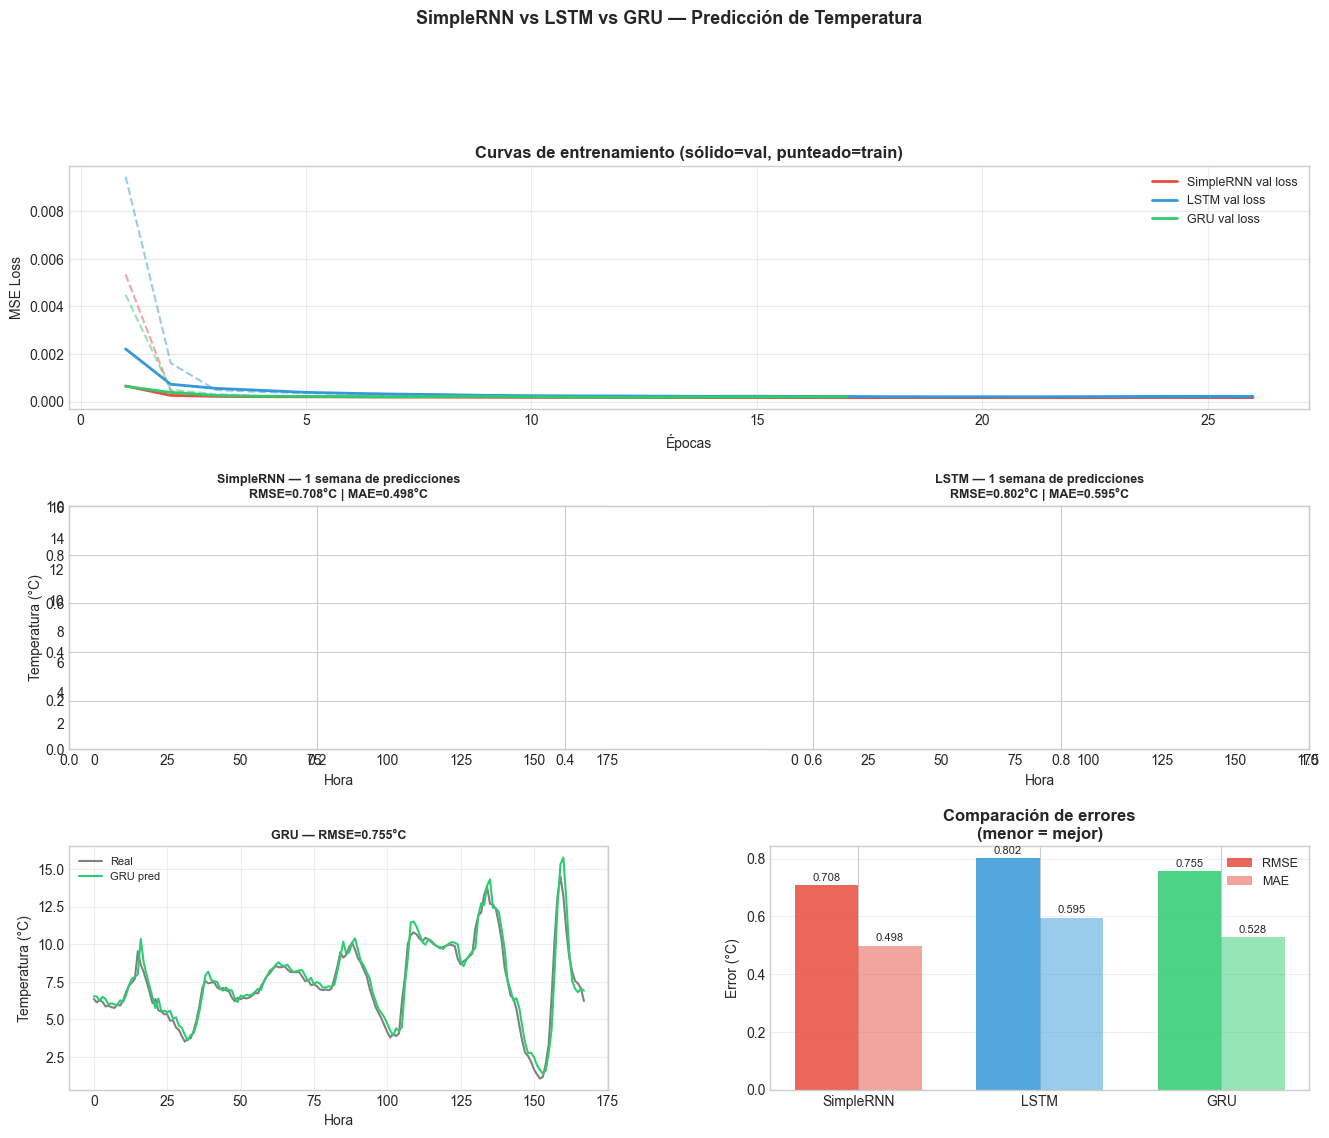

In [36]:
# Visualización completa de resultados
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 2, hspace=0.4, wspace=0.3)

colores = {'SimpleRNN': '#E74C3C', 'LSTM': '#3498DB', 'GRU': '#2ECC71'}

# Fila 1: curvas de entrenamiento
ax_loss = fig.add_subplot(gs[0, :])
for nombre, hist in [('SimpleRNN', hist_rnn), ('LSTM', hist_lstm), ('GRU', hist_gru)]:
    ep = range(1, len(hist.history['val_loss']) + 1)
    ax_loss.plot(ep, hist.history['val_loss'],
                 color=colores[nombre], lw=2, label=f'{nombre} val loss')
    ax_loss.plot(ep, hist.history['loss'],
                 color=colores[nombre], lw=1.5, linestyle='--', alpha=0.5)
ax_loss.set_title('Curvas de entrenamiento (sólido=val, punteado=train)',
                   fontweight='bold')
ax_loss.set_xlabel('Épocas'); ax_loss.set_ylabel('MSE Loss')
ax_loss.legend(fontsize=9); ax_loss.grid(alpha=0.4)

# Fila 2: predicciones vs real (primeras 168 horas = 1 semana)
N_VIS = 168
for col, (nombre, color) in enumerate(colores.items()):
    ax = fig.add_subplot(gs[1, col] if col < 2 else gs[1, :])
    if col < 2:
        ax.plot(res[nombre]['y_real'][:N_VIS], color='gray', lw=1.5,
                label='Real', alpha=0.8)
        ax.plot(res[nombre]['y_pred'][:N_VIS], color=color, lw=1.5,
                label=f'{nombre} pred')
        ax.set_title(f'{nombre} — 1 semana de predicciones\n'
                     f"RMSE={res[nombre]['rmse']:.3f}°C | MAE={res[nombre]['mae']:.3f}°C",
                     fontsize=9, fontweight='bold')
        ax.set_xlabel('Hora'); ax.set_ylabel('Temperatura (°C)')
        ax.legend(fontsize=8); ax.grid(alpha=0.3)

# GRU en fila 3
ax_gru = fig.add_subplot(gs[2, 0])
ax_gru.plot(res['GRU']['y_real'][:N_VIS], color='gray', lw=1.5, label='Real')
ax_gru.plot(res['GRU']['y_pred'][:N_VIS], color='#2ECC71', lw=1.5, label='GRU pred')
ax_gru.set_title(f"GRU — RMSE={res['GRU']['rmse']:.3f}°C", fontsize=9, fontweight='bold')
ax_gru.set_xlabel('Hora'); ax_gru.set_ylabel('Temperatura (°C)')
ax_gru.legend(fontsize=8); ax_gru.grid(alpha=0.3)

# Barras comparativas
ax_bar = fig.add_subplot(gs[2, 1])
nombres = list(res.keys())
rmses = [res[k]['rmse'] for k in nombres]
maes  = [res[k]['mae']  for k in nombres]
x = np.arange(len(nombres)); w = 0.35
bars1 = ax_bar.bar(x - w/2, rmses, w, label='RMSE',
                    color=[colores[k] for k in nombres], alpha=0.85)
bars2 = ax_bar.bar(x + w/2, maes,  w, label='MAE',
                    color=[colores[k] for k in nombres], alpha=0.5)
ax_bar.bar_label(bars1, fmt='{:.3f}', fontsize=8, padding=2)
ax_bar.bar_label(bars2, fmt='{:.3f}', fontsize=8, padding=2)
ax_bar.set_xticks(x); ax_bar.set_xticklabels(nombres)
ax_bar.set_title('Comparación de errores\n(menor = mejor)', fontweight='bold')
ax_bar.set_ylabel('Error (°C)'); ax_bar.legend(fontsize=9)
ax_bar.grid(alpha=0.3, axis='y')

plt.suptitle('SimpleRNN vs LSTM vs GRU — Predicción de Temperatura',
             fontsize=13, fontweight='bold', y=1.01)
plt.show()

### 6.5 Widget interactivo: explorador de predicciones

Navega por cualquier ventana del conjunto de test y compara las predicciones
de los tres modelos con el valor real.

In [37]:
# Precalcular predicciones en escala original
preds = {}
for modelo, nombre in [(model_rnn,'SimpleRNN'),(model_lstm,'LSTM'),(model_gru,'GRU')]:
    y_sc = modelo.predict(X_test, verbose=0).flatten()
    preds[nombre] = scaler.inverse_transform(y_sc.reshape(-1,1)).flatten()
y_real_orig = scaler.inverse_transform(y_test.reshape(-1,1)).flatten()

def explorar_prediccion_temp(inicio=0, ventana_vis=72):
    fin = min(inicio + ventana_vis, len(y_real_orig))
    idx = slice(inicio, fin)
    horas = np.arange(inicio, fin)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Panel izq: comparación de modelos
    axes[0].plot(horas, y_real_orig[idx], color='gray', lw=2.5,
                 label='Real', zorder=5)
    for nombre, color in colores.items():
        axes[0].plot(horas, preds[nombre][idx], color=color, lw=1.8,
                     linestyle='--', label=nombre, alpha=0.85)
    axes[0].set_title(f'Predicciones horas {inicio}–{fin}', fontweight='bold')
    axes[0].set_xlabel('Hora (test)'); axes[0].set_ylabel('Temperatura (°C)')
    axes[0].legend(fontsize=9); axes[0].grid(alpha=0.4)

    # Panel der: error por modelo
    for nombre, color in colores.items():
        error = np.abs(preds[nombre][idx] - y_real_orig[idx])
        axes[1].plot(horas, error, color=color, lw=1.5, label=f'|Error| {nombre}')
    axes[1].set_title('Error absoluto por modelo', fontweight='bold')
    axes[1].set_xlabel('Hora (test)'); axes[1].set_ylabel('|Error| (°C)')
    axes[1].legend(fontsize=9); axes[1].grid(alpha=0.4)

    plt.tight_layout(); plt.show()

    # Métricas del fragmento
    print('Métricas en este fragmento:')
    for nombre in colores:
        rmse_f = np.sqrt(mean_squared_error(y_real_orig[idx], preds[nombre][idx]))
        print(f'  {nombre}: RMSE={rmse_f:.3f}°C')

widgets.interact(
    explorar_prediccion_temp,
    inicio=widgets.IntSlider(value=0, min=0, max=len(y_real_orig)-100, step=24,
                              description='Inicio (hora):', continuous_update=False,
                              style={'description_width': '130px'},
                              layout=widgets.Layout(width='500px')),
    ventana_vis=widgets.IntSlider(value=72, min=24, max=240, step=24,
                                   description='Ventana (horas):', continuous_update=False,
                                   style={'description_width': '130px'},
                                   layout=widgets.Layout(width='500px')),
)

interactive(children=(IntSlider(value=0, continuous_update=False, description='Inicio (hora):', layout=Layout(…

<function __main__.explorar_prediccion_temp(inicio=0, ventana_vis=72)>

## 7. Análisis de resultados y lecciones aprendidas

### 7.1 ¿Qué capturaron los modelos?

Los modelos aprenden el **patrón diario** de la temperatura (valle en la madrugada,
pico a media tarde) porque ese patrón es robusto y repetido en el entrenamiento.
Lo que les cuesta son los **cambios bruscos** (una tormenta repentina, un día atípico)
porque son difíciles de predecir con historia reciente.

### 7.2 Tabla de lecciones

| Concepto | Evidencia en el notebook |
|----------|------------------------|
| RNN simple tiene memoria corta | Peor en cambios bruscos — los olvida |
| LSTM supera a RNN en dependencias largas | Menor RMSE, mejor manejo de tendencias |
| GRU ≈ LSTM con menos parámetros | Rendimiento similar, entrenamiento más rápido |
| División temporal es obligatoria | Si fuera aleatoria, habría data leakage |
| Normalización es crítica | Sin ella, el entrenamiento oscila y diverge |

## 8. Más allá de las RNNs: hacia los Transformers

Las RNNs, LSTMs y GRUs dominaron el procesamiento de secuencias durante la década 2010-2020.
Sin embargo, tienen dos limitaciones estructurales:

1. **Procesamiento secuencial**: el paso $t$ depende de $t-1$, imposibilitando la
   paralelización. Con secuencias largas, el entrenamiento es lento.
2. **Compresión de información**: toda la historia se comprime en $h_t$, lo que
   puede perder información aunque las compuertas mitiguen el vanishing gradient.

En 2017, el paper *'Attention is All You Need'* (Vaswani et al.) propuso los
**Transformers**: arquitecturas basadas en **mecanismos de atención** que permiten
que cada posición de la secuencia atienda directamente a cualquier otra posición,
sin importar la distancia temporal.

| Aspecto | RNN/LSTM/GRU | Transformer |
|---------|-------------|-------------|
| Paralelización |  Secuencial |  Totalmente paralelo |
| Dependencias largas |  Difícil (gradiente) |  Atención directa |
| Memoria de contexto | Comprimida en h_t | Cada token accede a todos |
| Escalabilidad | Limitada | GPT-4, LLaMA, BERT... |
| Datos necesarios | Menor cantidad | Grande cantidad |

> **¿Significa que las RNNs están obsoletas?** No del todo. Para datasets pequeños,
> dispositivos con recursos limitados, o problemas donde el orden estrictamente
> causal importa (como ciertos sensores IoT), las GRU/LSTM siguen siendo opciones
> prácticas y eficientes.

La transición RNN → Transformer es la historia más importante del Deep Learning
reciente — y la base de modelos como GPT, BERT, y Llama.

## 9. Ejercicios

### Ejercicio 3 — RNN apilada (*stacked*)

Construye una LSTM con **2 capas apiladas** (stacked LSTM) y compara su rendimiento
con la LSTM de 1 capa del caso práctico.

Para apilar capas recurrentes en Keras, todas las capas excepto la última
deben devolver la secuencia completa: `return_sequences=True`.

1. Construye y entrena la stacked LSTM.
2. Compara el RMSE en test con la LSTM de 1 capa.
3. ¿Cuántos parámetros adicionales tiene? ¿El costo computacional se justifica?

In [40]:
# Scaffold Ejercicio 3: LSTM apilada
tf_seed.random.set_seed(42)

model_stacked = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    layers.LSTM(64, return_sequences=True),  # devuelve secuencia para la siguiente capa
    layers.LSTM(32),                          # ultima capa recurrente
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])

model_stacked.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_stacked.summary()

# Entrenar
# hist_stacked = model_stacked.fit(
#     X_train, y_train,
#     validation_data=(X_val, y_val),
#     epochs=30, batch_size=256,
#     callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)],
#     verbose=0
# )

# Evaluar y comparar
# y_pred_st = model_stacked.predict(X_test, verbose=0).flatten()
# y_pred_st_orig = scaler.inverse_transform(y_pred_st.reshape(-1,1)).flatten()
# rmse_st = np.sqrt(mean_squared_error(y_real_orig, y_pred_st_orig))
# print(f'LSTM 1 capa:  RMSE = {res["LSTM"]["rmse"]:.4f}°C')
# print(f'LSTM 2 capas: RMSE = {rmse_st:.4f}°C')

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_5 (LSTM)                   │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,401 (118.75 KB)

 Trainable params: 30,401 (118.75 KB)

 Non-trainable params: 0 (0.00 B)

### Ejercicio 4 — Predicción multi-paso

Hasta ahora predijimos **1 hora adelante**. Extiende el modelo para predecir
las **próximas 6 horas** simultáneamente.

1. Usa `crear_ventanas(temp_scaled, 24, 6)` para generar el dataset.
2. Cambia la capa de salida a `Dense(6)` (6 pasos futuros).
3. Entrena y evalúa. ¿El error crece con el horizonte de predicción?
4. Visualiza las 6 predicciones para una ventana concreta.

In [41]:
# Scaffold Ejercicio 4: predicción multi-paso
X_ms, y_ms = crear_ventanas(temp_scaled, 24, 6)
X_ms = X_ms.reshape(X_ms.shape[0], 24, 1)
# y_ms tiene shape (n, 6) — 6 pasos futuros

n_tr_ms = int(len(X_ms) * 0.7)
n_vl_ms = int(len(X_ms) * 0.15)
X_tr_ms, y_tr_ms = X_ms[:n_tr_ms], y_ms[:n_tr_ms]
X_vl_ms, y_vl_ms = X_ms[n_tr_ms:n_tr_ms+n_vl_ms], y_ms[n_tr_ms:n_tr_ms+n_vl_ms]
X_ts_ms, y_ts_ms = X_ms[n_tr_ms+n_vl_ms:], y_ms[n_tr_ms+n_vl_ms:]

# Tu modelo multi-paso (cambia Dense(1) por Dense(6))
# model_multi = keras.Sequential([
#     layers.Input(shape=(24, 1)),
#     layers.LSTM(64),
#     layers.Dense(32, activation='relu'),
#     layers.Dense(6)   # <- 6 pasos futuros
# ])
# model_multi.compile(optimizer='adam', loss='mse')
# hist_multi = model_multi.fit(...)

# Visualizar las 6 predicciones para la muestra 0
# y_pred_multi = model_multi.predict(X_ts_ms[:1])
# pred_orig = scaler.inverse_transform(y_pred_multi).flatten()
# real_orig = scaler.inverse_transform(y_ts_ms[:1]).flatten()
# plt.plot(range(6), real_orig, 'o-', label='Real')
# plt.plot(range(6), pred_orig, 's--', label='Predicho')
# plt.xlabel('Horas en el futuro'); plt.legend(); plt.show()

### Ejercicio 5 — Regularización en RNNs

Las capas recurrentes de Keras soportan dos tipos de dropout:
- `dropout`: aplica dropout a las **entradas** $x_t$.
- `recurrent_dropout`: aplica dropout a las **conexiones recurrentes** $h_{t-1}$.

1. Entrena una LSTM con `dropout=0.2, recurrent_dropout=0.1` y compara con la sin dropout.
2. ¿El dropout recurrente ayuda más o menos que el dropout de entrada?
3. ¿Qué ocurre si usas un `recurrent_dropout` muy alto (0.5)?

> **Nota**: el `recurrent_dropout` no puede usarse con GPU de forma eficiente en
> TensorFlow — si tienes GPU, el entrenamiento será significativamente más lento.

In [43]:
# Scaffold Ejercicio 5: dropout en LSTM
tf_seed.random.set_seed(42)

model_dropout = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    layers.LSTM(64, dropout=0.2, recurrent_dropout=0.1),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])

model_dropout.compile(optimizer='adam', loss='mse', metrics=['mae'])
print('LSTM con dropout:')
model_dropout.summary()

# hist_dropout = model_dropout.fit(
#     X_train, y_train,
#     validation_data=(X_val, y_val),
#     epochs=30, batch_size=256,
#     callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)],
#     verbose=0
# )

# Compara con model_lstm entrenado antes:
# print(f'LSTM sin dropout: RMSE = {res["LSTM"]["rmse"]:.4f}°C')
# (calcula RMSE de model_dropout y compara)

LSTM con dropout:


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_7 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

### Ejercicio 6 — Integrador: nuevo dominio

Aplica todo lo aprendido a un nuevo problema secuencial de tu elección:

**Opción A**: predicción de precio de una acción (puedes usar `yfinance` para
descargar datos reales: `pip install yfinance; import yfinance as yf`).

**Opción B**: clasificación de sentimiento en reseñas (secuencias de palabras → positivo/negativo).
Usa el dataset IMDB disponible en `keras.datasets.imdb`.

**Opción C**: predicción del consumo eléctrico horario (disponible en Kaggle:
*'Hourly Energy Consumption'*).

Para el dominio que elijas:
1. Explora los datos e identifica la estructura temporal.
2. Prepara los datos en formato `(muestras, pasos_tiempo, features)`.
3. Entrena al menos dos arquitecturas (e.g., GRU vs LSTM).
4. Evalúa con métricas apropiadas y visualiza las predicciones.
5. Identifica qué tipo de dependencias temporales captura el modelo.

In [44]:
# Opción A: precio de una acción con yfinance
# !pip install yfinance -q
# import yfinance as yf
# df_acc = yf.download('AAPL', start='2018-01-01', end='2024-01-01', interval='1d')
# serie_precio = df_acc['Close'].values
# (Sigue el mismo pipeline que usamos con la temperatura)

# Opción B: sentimiento en IMDB
# (X_train_imdb, y_train_imdb), (X_test_imdb, y_test_imdb) = keras.datasets.imdb.load_data(num_words=10000)
# X_train_imdb = keras.preprocessing.sequence.pad_sequences(X_train_imdb, maxlen=200)
# (Cambia la tarea a clasificación binaria: ultima capa Dense(1, activation='sigmoid'))
# (Usa 'binary_crossentropy' como loss)

print('Implementa tu ejercicio integrador aqui.')
print('Sigue el mismo pipeline del caso practico de temperatura.')

Implementa tu ejercicio integrador aqui.
Sigue el mismo pipeline del caso practico de temperatura.
